# SAM vs SGD calibration on Fashion-MNIST

**Question.** Does sharpness-aware minimization (SAM) improve test accuracy and calibration over plain SGD for a small two-block convolutional network trained on Fashion-MNIST?

**What this does.** Learning rates (and SAM's neighbourhood size `rho`) are chosen on a validation split only, using validation NLL. The selected settings are then trained with five paired seeds per arm. Each final model is evaluated on the test split, with temperature scaling fitted on validation. Reported metrics are accuracy, ECE (15 equal-width bins), NLL, the multi-class Brier score and a top-label equal-count ACE. The headline is a 12-row paired family with paired 95% t-intervals and Holm correction.

**Data and model.** `mini_demo_data.json` is a 100-image stratified subset of the official Fashion-MNIST test set (10 per class), with an explicit train/val/test split of 60/20/20. The model is a two-block CNN (conv 32 → conv 64 → dense 128 → 10 classes). Every training run is resumable: finished runs are read from `results/` instead of retrained.

**What you will see.** A tuning table, a 12-row paired-difference table with intervals and Holm p-values, and a forest plot and reliability diagram.

**Scale.** This demo uses the original hyperparameters (40 epochs, the full learning-rate and rho grids, five seeds), but only 100 images instead of 60,000. The numbers it prints are a pipeline check, not the paper's results.

## Install dependencies

Colab already has numpy, scipy, matplotlib and torch at its own versions, so the `google.colab` guard skips them there. Locally the exact Colab versions are installed.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Not pre-installed on Colab, always install
_pip('psutil', 'loguru')

# Core packages (pre-installed on Colab, install locally to match Colab env).
# torch is left unpinned: this machine's pip constraint file (PIP_CONSTRAINT) only
# offers its patched MPS build, so Colab's torch 2.9.0+cpu cannot be installed here.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch')

## Imports and figure style

The original import block, followed by the shared figure style for this run.

In [2]:
import argparse
import csv
import gc
import json
import math
import sys
import threading
import time
from pathlib import Path

import numpy as np
import psutil
import torch
import torch.nn as nn
import torch.nn.functional as F
from loguru import logger
from scipy import optimize, stats
import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


## Data loading

The mini demo data is read from GitHub. If that fails (offline, or the file is not pushed yet), the local `mini_demo_data.json` next to this notebook is used.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-d46016-sharpness-aware-training-makes-small/main/round-2/experiment-3/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

data = load_data()
print(data["metadata"])
print("examples:", len(data["examples"]), "| splits:", {s: sum(e["split"] == s for e in data["examples"]) for s in ("train", "val", "test")})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
{'dataset': 'Fashion-MNIST official test set, 100-image stratified demo subset', 'image_shape': [28, 28], 'pixel_range': 'uint8 0-255, row-major', 'splits': {'train': 60, 'val': 20, 'test': 20}, 'source_files': ['t10k-images-idx3-ubyte', 't10k-labels-idx1-ubyte'], 'seed': 0}
examples: 100 | splits: {'train': 60, 'val': 20, 'test': 20}


## Config

Every tunable value lives here. The original script's values are kept in the comments beside each one. This version uses the original hyperparameters, so the only reduction is the data size (100 images instead of 60,000).

`WS` is the notebook's own folder; the original used the script's folder. The `results/` and `logs/` folders are cleared on each run, because `train_run` skips any run whose record already exists, which would otherwise mix results from a different config.

In [4]:
import shutil

# ---- Config (original values in comments) ----
WS = Path.cwd()                      # original: the script's own folder
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

TUNE_SEED = 101
FINAL_SEEDS = [0, 1, 2, 3, 4]        # five seeds; T_CRIT_DF4 below assumes df = 4
EPOCHS = 40
SAVE_EPOCHS = {5, 15, 40}            # epochs whose logits are saved
BATCH = 128
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
BN_MOMENTUM = 0.1
SGD_GRID = [0.001, 0.003, 0.01, 0.03]
SAM_LR_GRID = [0.001, 0.003, 0.01, 0.03]
SAM_RHO_GRID = [0.05, 0.1, 0.2]
REDUCED_LR_GRID = [0.003, 0.01, 0.03]
EXT_LR = 0.0003
PROJECTED_LIMIT_S = 4.5 * 3600      # time guard from the plan
RUN_LIMIT_S = 600                    # 10 minutes per 40-epoch run
N_BINS = 15
T_CRIT_DF4 = 2.776                   # two-sided 95% t critical value, df = 4
RAM_CAP_BYTES = 12 * 1024**3

# Fresh outputs for this config: train_run skips runs whose record already exists.
for _d in ("results", "logs"):
    shutil.rmtree(WS / _d, ignore_errors=True)
print("device:", DEVICE, "| epochs:", EPOCHS, "| SGD grid:", SGD_GRID, "| SAM grid:", SAM_LR_GRID, "x", SAM_RHO_GRID)

device: mps | epochs: 40 | SGD grid: [0.001, 0.003, 0.01, 0.03] | SAM grid: [0.001, 0.003, 0.01, 0.03] x [0.05, 0.1, 0.2]


## Logging and RAM guard

Logging writes to stdout and `logs/run.log`. On macOS the RAM cap is enforced by a watchdog thread rather than `RLIMIT_AS`.

In [5]:
def start_ram_watchdog(cap_bytes: int) -> None:
    """macOS cannot cap RLIMIT_AS; watch resident memory instead (aii-use-hardware)."""
    me = psutil.Process()

    def _watch() -> None:
        while True:
            rss = sum(p.memory_info().rss for p in [me, *me.children(recursive=True)])
            if rss > cap_bytes:
                print(f"RAM cap hit: {rss / 1024**3:.1f} GB", file=sys.stderr, flush=True)
                import os
                os._exit(137)
            time.sleep(1)

    threading.Thread(target=_watch, daemon=True).start()


def setup_logging(root: Path) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (root / "logs").mkdir(parents=True, exist_ok=True)
    logger.add(root / "logs" / "run.log", rotation="30 MB", level="DEBUG")

setup_logging(WS)
start_ram_watchdog(RAM_CAP_BYTES)
logger.info(f"root={WS} device={DEVICE} torch={torch.__version__}")

09:31:49|INFO   |root=/Volumes/aii-s20001/work/run_S_3Y_l0tX7Xe/4_gen_paper_repo/_4_gen_demo_art/notebook_workspaces/iter_2/art_v2M5ZOOHpgid device=mps torch=2.16.0.dev20261116


## Data: tensors from the loaded examples

Same steps as the original `load_data`: the training split sets the normalisation (mean and std), then all splits are normalised with it and moved to `DEVICE`.

In [6]:
def build_tensors(raw: dict) -> dict:
    ex = raw["examples"]

    def pick(split: str):
        rows = [e for e in ex if e["split"] == split]
        X = torch.tensor([e["pixels"] for e in rows], dtype=torch.float32).div(255.0).view(-1, 1, 28, 28)
        y = torch.tensor([e["label"] for e in rows], dtype=torch.long)
        return X, y

    Xtr_raw, ytr = pick("train")
    Xva, yva = pick("val")
    Xte, yte = pick("test")
    assert Xtr_raw.shape[1:] == (1, 28, 28), Xtr_raw.shape
    mu = Xtr_raw.mean()
    sd = Xtr_raw.std()
    logger.info(f"Normalisation from the training split: mean={mu.item():.4f} std={sd.item():.4f}")

    def norm(t: torch.Tensor) -> torch.Tensor:
        return ((t - mu) / sd).contiguous()

    tensors = {
        "Xtr": norm(Xtr_raw).to(DEVICE),
        "ytr": ytr.to(DEVICE),
        "Xva": norm(Xva).to(DEVICE),
        "Xte": norm(Xte).to(DEVICE),
        "yva_np": yva.numpy(),
        "yte_np": yte.numpy(),
    }
    logger.info(f"Data ready on {DEVICE}: train {tuple(tensors['Xtr'].shape)}, "
                f"val {tuple(tensors['Xva'].shape)}, test {tuple(tensors['Xte'].shape)}")
    return tensors

tensors = build_tensors(data)

09:31:49|INFO   |Normalisation from the training split: mean=0.2966 std=0.3511


09:31:49|INFO   |Data ready on mps: train (60, 1, 28, 28), val (20, 1, 28, 28), test (20, 1, 28, 28)


## Model and training

A two-block CNN with batch norm, trained with SGD (momentum, cosine learning-rate schedule). The SAM arm takes an extra perturbed step at each batch, with BN running statistics frozen on that pass. Each run saves its logits at the `SAVE_EPOCHS` epochs.

In [7]:
# ----------------------------------------------------------------------------
# Model and training
# ----------------------------------------------------------------------------

class Net(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.f(x)


def run_name(kind: str, lr: float, rho: float, seed: int, tag: str = "") -> str:
    name = f"{kind}_lr{lr:g}_rho{rho:g}_seed{seed}"
    return f"{name}_{tag}" if tag else name


@torch.no_grad()
def evaluate_logits(model: nn.Module, X: torch.Tensor) -> np.ndarray:
    model.eval()
    outs = []
    for i in range(0, X.shape[0], 1000):
        outs.append(model(X[i:i + 1000]).float().cpu())
    model.train()
    return torch.cat(outs).numpy().astype(np.float32)


def train_run(data: dict, *, kind: str, lr: float, rho: float, seed: int,
              epochs: int, root: Path, tag: str = "") -> dict:
    """Train one model. kind is 'sgd' or 'sam'. Resumable: skips a finished run."""
    assert kind in ("sgd", "sam")
    name = run_name(kind, lr, rho, seed, tag)
    runs_dir = root / "results" / "runs"
    logits_dir = root / "results" / "logits"
    runs_dir.mkdir(parents=True, exist_ok=True)
    logits_dir.mkdir(parents=True, exist_ok=True)
    rec_path = runs_dir / f"{name}.json"
    if rec_path.exists():
        logger.info(f"skip finished run {name}")
        return json.loads(rec_path.read_text())

    logger.info(f"START {name} epochs={epochs} device={DEVICE}")
    torch.manual_seed(seed)
    model = Net().to(DEVICE)
    params = list(model.parameters())
    bns = [m for m in model.modules() if isinstance(m, nn.BatchNorm2d)]
    base = torch.optim.SGD(params, lr=lr, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)

    N = data["Xtr"].shape[0]
    steps_per_epoch = math.ceil(N / BATCH)
    total_steps = epochs * steps_per_epoch
    sched = torch.optim.lr_scheduler.LambdaLR(
        base, lambda t: 0.5 * (1.0 + math.cos(math.pi * min(t, total_steps) / total_steps)))
    gen = torch.Generator().manual_seed(seed)  # shared data order across kinds
    save_eps = SAVE_EPOCHS if epochs == EPOCHS else {epochs}

    epoch_loss: list[float] = []
    epoch_wall: list[float] = []
    val_logits = test_logits = None
    t_run0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        model.train()
        perm = torch.randperm(N, generator=gen)
        loss_sum = torch.zeros((), device=DEVICE)
        for i in range(0, N, BATCH):
            idx = perm[i:i + BATCH].to(DEVICE)
            xb = data["Xtr"][idx]
            yb = data["ytr"][idx]
            loss = F.cross_entropy(model(xb), yb)  # unperturbed first pass
            loss_sum += loss.detach() * yb.shape[0]
            loss.backward()
            if kind == "sam":
                with torch.no_grad():
                    gn = torch.sqrt(torch.stack([p.grad.pow(2).sum() for p in params]).sum())
                    eps = [rho * p.grad / (gn + 1e-12) for p in params]
                    for p, e in zip(params, eps):
                        p.add_(e)
                base.zero_grad()
                for m in bns:
                    m.momentum = 0.0  # freeze BN running stats on the perturbed pass
                F.cross_entropy(model(xb), yb).backward()
                for m in bns:
                    m.momentum = BN_MOMENTUM
                with torch.no_grad():
                    for p, e in zip(params, eps):
                        p.sub_(e)
            base.step()
            base.zero_grad()
            sched.step()
        ep_loss = float(loss_sum.item()) / N
        epoch_loss.append(ep_loss)
        dt = time.perf_counter() - t0
        epoch_wall.append(dt)
        if not math.isfinite(ep_loss):
            logger.warning(f"{name} epoch {ep}: non-finite training loss")
        logger.info(f"{name} ep {ep}/{epochs} train_loss={ep_loss:.4f} epoch_s={dt:.1f}")
        if ep in save_eps:
            val_logits = evaluate_logits(model, data["Xva"])
            test_logits = evaluate_logits(model, data["Xte"])
            np.savez(logits_dir / f"{name}_ep{ep}.npz", val=val_logits, test=test_logits)

    wall = time.perf_counter() - t_run0
    val_m = metrics(val_logits, data["yva_np"])
    rec = {
        "name": name, "kind": kind, "lr": lr, "rho": rho if kind == "sam" else 0.0,
        "seed": seed, "tag": tag, "epochs": epochs, "device": str(DEVICE),
        "batch_size": BATCH, "momentum": MOMENTUM, "weight_decay": WEIGHT_DECAY,
        "final_train_loss": epoch_loss[-1], "epoch_train_loss": epoch_loss,
        "epoch_wall_s": epoch_wall, "wall_time_s": wall,
        "val_nll": val_m["nll"], "val_ece": val_m["ece"], "val_acc": val_m["acc"],
        "val_brier": val_m["brier"], "val_ace": val_m["ace"],
        "logits_finite": bool(np.isfinite(val_logits).all()),
    }
    rec_path.write_text(json.dumps(rec, indent=2))
    with (root / "logs" / "timings.jsonl").open("a") as fh:
        fh.write(json.dumps({"name": name, "epochs": epochs, "wall_time_s": wall,
                             "mean_epoch_s": float(np.mean(epoch_wall)),
                             "device": str(DEVICE)}) + "\n")
    logger.info(f"DONE {name} wall={wall:.1f}s val_nll={val_m['nll']:.4f} "
                f"val_acc={val_m['acc']:.4f} final_train_loss={epoch_loss[-1]:.4f}")
    del model, base, sched, params, bns
    gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    return rec

## Metrics

Accuracy, NLL, Brier score, ECE (15 equal-width bins) and ACE (top-label, equal-count bins). Temperature is fitted on the validation logits only.

In [8]:
# ----------------------------------------------------------------------------
# Metrics
# ----------------------------------------------------------------------------

def log_softmax_np(z: np.ndarray) -> np.ndarray:
    z = z.astype(np.float64)
    z = z - z.max(axis=1, keepdims=True)
    return z - np.log(np.exp(z).sum(axis=1, keepdims=True))


def nll_of(logits: np.ndarray, y: np.ndarray) -> float:
    lp = log_softmax_np(logits)
    return float(-lp[np.arange(len(y)), y].mean())


def ece_equal_width(conf: np.ndarray, correct: np.ndarray, nb: int = N_BINS) -> float:
    """ECE with nb equal-width bins on max-softmax confidence (Guo et al. 2017)."""
    b = np.clip(np.ceil(conf * nb).astype(int) - 1, 0, nb - 1)
    n = len(conf)
    ece = 0.0
    for k in range(nb):
        m = b == k
        if m.any():
            ece += m.sum() / n * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def ace_equal_count(conf: np.ndarray, correct: np.ndarray, nb: int = N_BINS) -> float:
    """Top-label adaptive calibration error: mean |acc - conf| over nb equal-count bins
    (quantile bins of max-softmax confidence). Simplified from Nixon et al. (2019),
    which is per-class; the report states this."""
    order = np.argsort(conf, kind="stable")
    gaps = []
    for g in np.array_split(order, nb):
        if len(g) > 0:
            gaps.append(abs(correct[g].mean() - conf[g].mean()))
    return float(np.mean(gaps))


def metrics(logits: np.ndarray | None, y: np.ndarray) -> dict:
    nan = float("nan")
    if logits is None or not np.isfinite(logits).all():
        return {"acc": nan, "nll": nan, "brier": nan, "ece": nan, "ace": nan}
    lp = log_softmax_np(logits)
    p = np.exp(lp)
    pred = logits.argmax(axis=1)
    correct = (pred == y).astype(np.float64)
    conf = p.max(axis=1)
    onehot = np.eye(10)[y]
    return {
        "acc": float(correct.mean()),
        "nll": float(-lp[np.arange(len(y)), y].mean()),
        "brier": float(((p - onehot) ** 2).sum(axis=1).mean()),
        "ece": ece_equal_width(conf, correct),
        "ace": ace_equal_count(conf, correct),
    }


def fit_temperature(val_logits: np.ndarray, yva: np.ndarray) -> float:
    res = optimize.minimize_scalar(lambda t: nll_of(val_logits / t, yva),
                                   bounds=(0.05, 10.0), method="bounded",
                                   options={"xatol": 1e-6})
    return float(res.x)

## Stage 1: tuning on validation only

Learning rates and `rho` are compared by final-epoch validation NLL at tuning seed 101. A time guard projects the total runtime first. If the lowest grid learning rate is selected, the extension value `0.0003` is also tried. The selected settings go to `results/selection.json`.

In [9]:
# ----------------------------------------------------------------------------
# Stages
# ----------------------------------------------------------------------------

def select_best(rows: list[dict], kind: str) -> dict:
    cand = [r for r in rows if r["kind"] == kind]
    if not cand:
        raise RuntimeError(f"no {kind} configurations")

    def key(r: dict) -> float:
        v = r["val_nll"]
        return v if (v is not None and math.isfinite(v)) else float("inf")

    best = min(cand, key=key)
    if not math.isfinite(key(best)):
        raise RuntimeError(f"every {kind} configuration diverged; nothing can be selected")
    return best


def write_tuning_table(rows: list[dict], root: Path) -> None:
    out = root / "results" / "tuning_table.csv"
    out.parent.mkdir(parents=True, exist_ok=True)
    cols = ["kind", "lr", "rho", "seed", "epochs", "val_nll", "val_ece", "val_acc",
            "final_train_loss", "wall_time_s", "device", "name"]
    with out.open("w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=cols)
        w.writeheader()
        for r in sorted(rows, key=lambda r: (r["kind"], r["lr"], r["rho"])):
            w.writerow({
                "kind": r["kind"], "lr": r["lr"], "rho": r["rho"], "seed": r["seed"],
                "epochs": r["epochs"], "val_nll": r["val_nll"], "val_ece": r["val_ece"],
                "val_acc": r["val_acc"], "final_train_loss": r["final_train_loss"],
                "wall_time_s": r["wall_time_s"], "device": r["device"], "name": r["name"],
            })
    logger.info(f"Wrote {out} ({len(rows)} rows)")


def load_runs(root: Path) -> list[dict]:
    return [json.loads(p.read_text()) for p in sorted((root / "results" / "runs").glob("*.json"))]


def stage_tune(data: dict, root: Path) -> None:
    tune_rows: list[dict] = []

    def go(kind: str, lr: float, rho: float) -> None:
        r = train_run(data, kind=kind, lr=lr, rho=rho, seed=TUNE_SEED,
                      epochs=EPOCHS, root=root, tag="tune")
        tune_rows.append(r)
        write_tuning_table(tune_rows, root)

    # Timing configs first (they are also grid members): time guard before the sweep.
    go("sgd", 0.01, 0.0)
    go("sam", 0.01, 0.1)
    t_sgd = next(r for r in tune_rows if r["kind"] == "sgd")["wall_time_s"]
    t_sam = next(r for r in tune_rows if r["kind"] == "sam")["wall_time_s"]

    # Plan: sgd 4 + sam 12, extension up to 2 sgd + 3 sam, finals 5 + 5, determinism 1.
    n_sgd_left = len(SGD_GRID) - 1 + 2 + 5 + 1
    n_sam_left = len(SAM_LR_GRID) * len(SAM_RHO_GRID) - 1 + 3 + 5
    projected = t_sgd * n_sgd_left + t_sam * n_sam_left
    too_slow = max(t_sgd, t_sam) > RUN_LIMIT_S
    reduced = projected > PROJECTED_LIMIT_S or too_slow
    guard = {
        "t_sgd_40ep_s": t_sgd, "t_sam_40ep_s": t_sam,
        "projected_total_s": projected, "limit_s": PROJECTED_LIMIT_S,
        "run_limit_s": RUN_LIMIT_S, "reduced_grid": reduced,
        "reason": ("a 40-epoch run exceeded 10 minutes" if too_slow else
                   "projected total exceeds 4.5 h" if projected > PROJECTED_LIMIT_S else
                   "full grid fits the time budget"),
    }
    (root / "logs").mkdir(parents=True, exist_ok=True)
    (root / "logs" / "time_guard.json").write_text(json.dumps(guard, indent=2))
    logger.info(f"TIME GUARD: {guard}")

    sgd_grid = REDUCED_LR_GRID if reduced else SGD_GRID
    sam_lr_grid = REDUCED_LR_GRID if reduced else SAM_LR_GRID
    for lr in sgd_grid:
        if lr != 0.01:
            go("sgd", lr, 0.0)
    for lr in sam_lr_grid:
        for rho in SAM_RHO_GRID:
            if (lr, rho) != (0.01, 0.1):
                go("sam", lr, rho)

    # Extension rule: lowest grid value selected -> also run 0.0003, then re-select.
    best_sgd = select_best(tune_rows, "sgd")
    if best_sgd["lr"] == 0.001:
        logger.info("SGD selected lr is 0.001: running extension lr 0.0003")
        go("sgd", EXT_LR, 0.0)
        best_sgd = select_best(tune_rows, "sgd")
    best_sam = select_best(tune_rows, "sam")
    if best_sam["lr"] == 0.001:
        logger.info("SAM selected lr is 0.001: running extension lr 0.0003 with all rho")
        for rho in SAM_RHO_GRID:
            go("sam", EXT_LR, rho)
        best_sam = select_best(tune_rows, "sam")

    sel = {
        "tuning_seed": TUNE_SEED,
        "selection_criterion": "final-epoch validation NLL (raw logits), lowest wins",
        "sgd": {"lr": best_sgd["lr"], "rho": 0.0, "val_nll": best_sgd["val_nll"]},
        "sam": {"lr": best_sam["lr"], "rho": best_sam["rho"], "val_nll": best_sam["val_nll"]},
        "sgd_at_lower_grid_edge_of_final_grid": best_sgd["lr"] == min(sgd_grid + [EXT_LR]),
        "sam_at_lower_grid_edge_of_final_grid": best_sam["lr"] == min(sam_lr_grid + [EXT_LR]),
        "extension_0003_run": any(r["lr"] == EXT_LR for r in tune_rows),
        "reduced_grid": reduced,
    }
    write_tuning_table(tune_rows, root)
    (root / "results" / "selection.json").write_text(json.dumps(sel, indent=2))
    logger.info(f"SELECTED: {sel}")

## Stage 2: final paired seeds

Each selected setting is trained with five paired seeds (SGD and SAM share the seed, so the initialisation and data order match). A determinism rerun checks the logits of one SGD seed.

In [10]:
def stage_final(data: dict, root: Path) -> None:
    sel = json.loads((root / "results" / "selection.json").read_text())
    for seed in FINAL_SEEDS:
        train_run(data, kind="sgd", lr=sel["sgd"]["lr"], rho=0.0, seed=seed,
                  epochs=EPOCHS, root=root)
        train_run(data, kind="sam", lr=sel["sam"]["lr"], rho=sel["sam"]["rho"], seed=seed,
                  epochs=EPOCHS, root=root)

    # Determinism check: rerun SGD seed 0 at the selected lr and compare logits.
    det = train_run(data, kind="sgd", lr=sel["sgd"]["lr"], rho=0.0, seed=0,
                    epochs=EPOCHS, root=root, tag="det")
    logits_dir = root / "results" / "logits"
    orig = np.load(logits_dir / f"{run_name('sgd', sel['sgd']['lr'], 0.0, 0)}_ep{EPOCHS}.npz")
    rerun = np.load(logits_dir / f"{run_name('sgd', sel['sgd']['lr'], 0.0, 0, 'det')}_ep{EPOCHS}.npz")
    max_diff_val = float(np.abs(orig["val"] - rerun["val"]).max())
    max_diff_test = float(np.abs(orig["test"] - rerun["test"]).max())
    acc_orig = metrics(orig["test"], data["yte_np"])["acc"]
    acc_rerun = metrics(rerun["test"], data["yte_np"])["acc"]
    out = {
        "max_abs_logit_diff_val": max_diff_val,
        "max_abs_logit_diff_test": max_diff_test,
        "test_acc_original": acc_orig, "test_acc_rerun": acc_rerun,
        "device": str(DEVICE),
        "note": "Difference is MPS nondeterminism unless it is large; a large difference "
                "means the shared-init or shared-order claim is broken.",
    }
    (root / "logs" / "determinism.json").write_text(json.dumps(out, indent=2))
    logger.info(f"DETERMINISM: {out}")

## Stage 3: analysis on the test split

Temperature is fitted on validation for every final model. The 12-row paired family has paired t-intervals and Holm correction. Pooled reliability bins and a placebo (shuffled test labels) are written out, along with `method_out.json`.

In [11]:
def paired_row(name: str, diffs: np.ndarray) -> dict:
    d = np.asarray(diffs, dtype=np.float64)
    n = len(d)
    mean = float(d.mean())
    sd = float(d.std(ddof=1))
    se = sd / math.sqrt(n)
    t = mean / se if se > 0 else float("nan")
    p = float(2 * stats.t.sf(abs(t), df=n - 1)) if math.isfinite(t) else float("nan")
    half = T_CRIT_DF4 * se
    return {"row": name, "per_seed_diff": d.tolist(), "mean": mean, "sd": sd,
            "t": t, "df": n - 1, "ci95_low": mean - half, "ci95_high": mean + half,
            "p_two_sided": p}


def holm(rows: list[dict]) -> None:
    m = len(rows)
    order = sorted(range(m), key=lambda i: rows[i]["p_two_sided"])
    adj = [0.0] * m
    running = 0.0
    for rank, i in enumerate(order):
        val = min(1.0, (m - rank) * rows[i]["p_two_sided"])
        running = max(running, val)
        adj[i] = running
    for i, r in enumerate(rows):
        r["p_holm"] = adj[i]
        r["significant_holm_0_05"] = bool(adj[i] < 0.05)


def reliability_bins(conf: np.ndarray, correct: np.ndarray, nb: int = N_BINS) -> list[dict]:
    b = np.clip(np.ceil(conf * nb).astype(int) - 1, 0, nb - 1)
    out = []
    for k in range(nb):
        m = b == k
        n = int(m.sum())
        out.append({
            "bin": k, "lower": k / nb, "upper": (k + 1) / nb, "count": n,
            "mean_confidence": float(conf[m].mean()) if n else None,
            "accuracy": float(correct[m].mean()) if n else None,
        })
    return out


def stage_analyze(data: dict, root: Path) -> None:
    sel = json.loads((root / "results" / "selection.json").read_text())
    logits_dir = root / "results" / "logits"
    yva, yte = data["yva_np"], data["yte_np"]

    per_seed = {"sgd_raw": [], "sgd_ts": [], "sam_raw": [], "sam_ts": []}
    temps = {"sgd": [], "sam": []}
    train_loss = {"sgd": [], "sam": []}
    raw_test = {"sgd": [], "sam": []}
    run_records = {}

    for seed in FINAL_SEEDS:
        for kind, lr, rho in (("sgd", sel["sgd"]["lr"], 0.0),
                              ("sam", sel["sam"]["lr"], sel["sam"]["rho"])):
            name = run_name(kind, lr, rho, seed)
            rec = json.loads((root / "results" / "runs" / f"{name}.json").read_text())
            run_records[name] = rec
            train_loss[kind].append(rec["final_train_loss"])
            z = np.load(logits_dir / f"{name}_ep{EPOCHS}.npz")
            T = fit_temperature(z["val"], yva)  # validation only
            temps[kind].append(T)
            raw_test[kind].append(z["test"])
            per_seed[f"{kind}_raw"].append(metrics(z["test"], yte))
            per_seed[f"{kind}_ts"].append(metrics(z["test"] / T, yte))
            logger.info(f"{name}: T={T:.4f} test raw={per_seed[f'{kind}_raw'][-1]} "
                        f"ts={per_seed[f'{kind}_ts'][-1]}")

    def col(arm: str, key: str) -> np.ndarray:
        return np.array([m[key] for m in per_seed[arm]])

    family = []
    for key, label in (("acc", "accuracy"), ("ece", "ECE"), ("nll", "NLL"),
                       ("brier", "Brier"), ("ace", "ACE")):
        family.append(paired_row(f"SAM - SGD: {label}", col("sam_raw", key) - col("sgd_raw", key)))
    for key, label in (("acc", "accuracy"), ("ece", "ECE"), ("nll", "NLL"),
                       ("brier", "Brier"), ("ace", "ACE")):
        family.append(paired_row(f"SAM - TS-SGD: {label}", col("sam_ts", key) - col("sgd_ts", key)))
    for key, label in (("ece", "ECE"), ("nll", "NLL")):
        family.append(paired_row(f"TS-SAM - TS-SGD: {label}", col("sam_ts", key) - col("sgd_ts", key)))
    assert len(family) == 12
    holm(family)
    for r in family:
        logger.info(f"{r['row']}: mean={r['mean']:+.5f} CI=[{r['ci95_low']:+.5f},{r['ci95_high']:+.5f}] "
                    f"p={r['p_two_sided']:.4f} holm={r['p_holm']:.4f}")

    # Pooled reliability bins per arm (all seeds pooled), raw and temperature-scaled.
    bins = {}
    for arm, logits_list, T_list in (
            ("sgd_raw", raw_test["sgd"], [1.0] * 5),
            ("sam_raw", raw_test["sam"], [1.0] * 5),
            ("sgd_ts", raw_test["sgd"], temps["sgd"]),
            ("sam_ts", raw_test["sam"], temps["sam"])):
        confs, corrs = [], []
        for z, T in zip(logits_list, T_list):
            lp = log_softmax_np(z / T)
            p = np.exp(lp)
            confs.append(p.max(axis=1))
            corrs.append((z.argmax(axis=1) == yte).astype(np.float64))
        bins[arm] = reliability_bins(np.concatenate(confs), np.concatenate(corrs))
    (root / "results" / "reliability_bins.json").write_text(json.dumps(
        {"n_bins": N_BINS, "binning": "15 equal-width bins on max-softmax confidence, "
         "all five seeds pooled per arm, test images per seed", "arms": bins}, indent=2))

    # Placebo: evaluate both arms against shuffled test labels. The SAM-minus-SGD
    # difference should not be significant; a significant result would mean the
    # arm difference is not tied to label information.
    shuf = np.random.default_rng(12345).permutation(yte)
    placebo_per = {"sgd": [], "sam": []}
    for kind in ("sgd", "sam"):
        for z in raw_test[kind]:
            placebo_per[kind].append(metrics(z, shuf))
    placebo_rows = []
    for key in ("acc", "nll", "ece", "brier", "ace"):
        d = np.array([placebo_per["sam"][i][key] - placebo_per["sgd"][i][key] for i in range(5)])
        placebo_rows.append(paired_row(f"PLACEBO SAM - SGD (shuffled test labels): {key}", d))
    holm(placebo_rows)
    self_diff = np.zeros(5)  # an arm compared with itself is identically zero
    self_row = paired_row("PLACEBO SGD - SGD (same model)", self_diff)

    tables = {
        "family_of_12_paired": family,
        "placebo": placebo_rows + [self_row],
        "per_seed_metrics": {k: v for k, v in per_seed.items()},
        "temperature_T": temps,
        "final_train_loss": train_loss,
        "run_records": run_records,
    }
    (root / "results" / "analysis_tables.json").write_text(json.dumps(tables, indent=2))

    # method_out.json in the aii-json exp_gen_sol_out shape: one example per test image
    # (all test images), the true class as output, and one predict_* field per final model and seed.
    classes = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
    predictions = {}
    for kind in ("sgd", "sam"):
        for i, seed in enumerate(FINAL_SEEDS):
            predictions[f"predict_{kind}_seed{seed}"] = raw_test[kind][i].argmax(axis=1)
    examples = []
    for j in range(len(yte)):
        ex = {
            "input": f"Fashion-MNIST test image {j} (28x28 grayscale). Classify the clothing item.",
            "output": classes[int(yte[j])],
            "metadata_test_index": j,
            "metadata_true_label": int(yte[j]),
        }
        for key, arr in predictions.items():
            ex[key] = classes[int(arr[j])]
        examples.append(ex)
    logger.info(f"method_out examples: {len(examples)} test images, {len(predictions)} predict fields each")
    method_out = {
        "metadata": {
            "method_name": "SAM vs SGD calibration on Fashion-MNIST (retuned)",
            "description": "Five paired seeds, validation-only tuning at seed 101, temperature "
                           "scaling fitted on validation, 12-row paired family with Holm correction.",
            "selection": sel,
            "family_of_12_paired": family,
            "placebo": tables["placebo"],
            "temperature_T": temps,
            "final_train_loss": train_loss,
            "reliability_bins_file": "results/reliability_bins.json",
            "ace_note": "Top-label, equal-count binned variant; not comparable to per-class ACE values.",
        },
        "datasets": [{"dataset": "FashionMNIST_test_demo", "examples": examples}],
    }
    (root / "results" / "method_out.json").write_text(json.dumps(method_out, indent=2))
    logger.info("Wrote results/method_out.json and analysis tables")

## Run the three stages

The original script ran one stage per command line (`--stage tune`, `final`, `analyze`). Here they run in order in one cell. The final stage needs the selection from the tuning stage, so the order matters.

In [12]:
stage_tune(tensors, WS)
stage_final(tensors, WS)
stage_analyze(tensors, WS)
logger.info("All three stages finished.")

09:31:49|INFO   |START sgd_lr0.01_rho0_seed101_tune epochs=40 device=mps


09:31:51|INFO   |sgd_lr0.01_rho0_seed101_tune ep 1/40 train_loss=2.3106 epoch_s=1.6


09:31:51|INFO   |sgd_lr0.01_rho0_seed101_tune ep 2/40 train_loss=2.1634 epoch_s=0.0


09:31:51|INFO   |sgd_lr0.01_rho0_seed101_tune ep 3/40 train_loss=1.9434 epoch_s=0.0


09:31:51|INFO   |sgd_lr0.01_rho0_seed101_tune ep 4/40 train_loss=1.7045 epoch_s=0.0


09:31:51|INFO   |sgd_lr0.01_rho0_seed101_tune ep 5/40 train_loss=1.4414 epoch_s=0.0


... (1,169 outputs left out)

09:32:02|INFO   |TS-SAM - TS-SGD: NLL: mean=+0.01462 CI=[-0.00676,+0.03600] p=0.1305 holm=1.0000


09:32:02|INFO   |method_out examples: 20 test images, 10 predict fields each


09:32:02|INFO   |Wrote results/method_out.json and analysis tables


09:32:02|INFO   |All three stages finished.


## Results

The 12-row paired family (mean difference, 95% t-interval, Holm-adjusted p), the selected settings, and two plots: the paired differences with their intervals, and pooled reliability curves for raw and temperature-scaled models.

Selected: SGD lr 0.01 | SAM lr 0.01 rho 0.05
row                                  mean diff     CI low    CI high   p Holm
SAM - SGD: accuracy                   -0.03000   -0.08552   +0.02552   1.0000
SAM - SGD: ECE                        -0.02155   -0.09673   +0.05364   1.0000
SAM - SGD: NLL                        +0.00786   -0.01940   +0.03511   1.0000
SAM - SGD: Brier                      -0.00651   -0.01114   -0.00187   0.2107
SAM - SGD: ACE                        -0.00821   -0.03305   +0.01663   1.0000
SAM - TS-SGD: accuracy                -0.03000   -0.08552   +0.02552   1.0000
SAM - TS-SGD: ECE                     +0.01578   -0.11269   +0.14426   1.0000
SAM - TS-SGD: NLL                     +0.01462   -0.00676   +0.03600   1.0000
SAM - TS-SGD: Brier                   -0.00339   -0.00634   -0.00044   0.3641
SAM - TS-SGD: ACE                     -0.00954   -0.03066   +0.01159   1.0000
TS-SAM - TS-SGD: ECE                  +0.01578   -0.11269   +0.14426   1.0000
TS-SAM - TS-SGD: NL

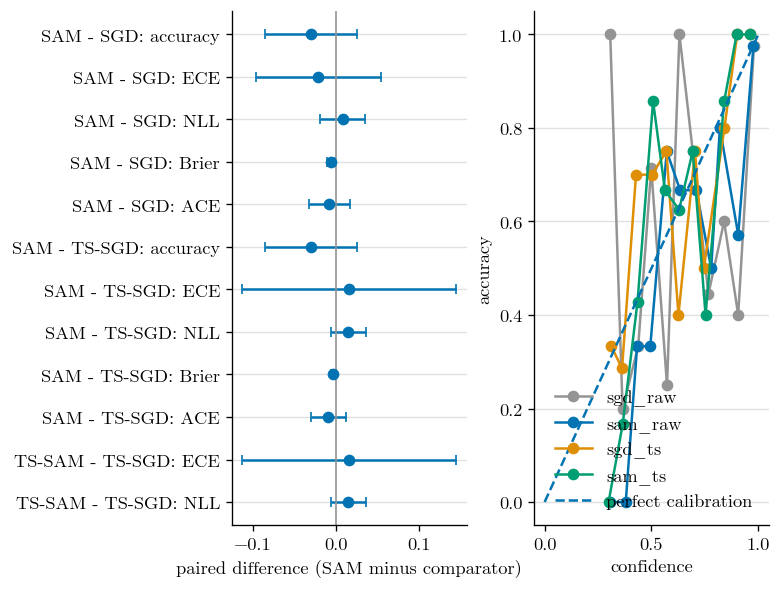

In [13]:
analysis = json.loads((WS / "results" / "analysis_tables.json").read_text())
selection = json.loads((WS / "results" / "selection.json").read_text())
print("Selected: SGD lr", selection["sgd"]["lr"], "| SAM lr", selection["sam"]["lr"], "rho", selection["sam"]["rho"])

rows = analysis["family_of_12_paired"]
print(f"{'row':<34}{'mean diff':>12}{'CI low':>11}{'CI high':>11}{'p Holm':>9}")
for r in rows:
    print(f"{r['row']:<34}{r['mean']:>+12.5f}{r['ci95_low']:>+11.5f}{r['ci95_high']:>+11.5f}{r['p_holm']:>9.4f}")

fig, (ax_f, ax_r) = plt.subplots(1, 2)

# Forest plot: mean paired difference with its 95% interval, one row per comparison.
ypos = np.arange(len(rows))[::-1]
ax_f.errorbar([r["mean"] for r in rows], ypos,
              xerr=[[r["mean"] - r["ci95_low"] for r in rows], [r["ci95_high"] - r["mean"] for r in rows]],
              fmt="o", color=COLOURS["method"], capsize=3)
ax_f.axvline(0, color=COLOURS["baseline"], linewidth=1)
ax_f.set_yticks(ypos, [r["row"] for r in rows])
ax_f.set_xlabel("paired difference (SAM minus comparator)")

# Reliability curves: pooled over seeds, raw and temperature-scaled.
bins_all = json.loads((WS / "results" / "reliability_bins.json").read_text())["arms"]
for arm, colour in (("sgd_raw", COLOURS["baseline"]), ("sam_raw", COLOURS["method"]),
                    ("sgd_ts", COLOURS["other_1"]), ("sam_ts", COLOURS["other_2"])):
    pts = [(b["mean_confidence"], b["accuracy"]) for b in bins_all[arm] if b["count"] > 0]
    ax_r.plot([p[0] for p in pts], [p[1] for p in pts], marker="o", color=colour, label=arm)
ax_r.plot([0, 1], [0, 1], linestyle="--", label="perfect calibration")
ax_r.set_xlabel("confidence")
ax_r.set_ylabel("accuracy")
ax_r.legend()
plt.show()

## Interpreting the results

Read these outputs against the claim being tested. The question is whether SAM improves accuracy and calibration over SGD. The table shows the mean paired difference (SAM minus the comparator) with a 95% t-interval and a Holm-adjusted p-value over the 12 rows. A row is a real difference when its interval excludes zero and its Holm p is below 0.05. For the calibration rows, the temperature-scaled comparisons separate "SAM is better calibrated" from "SAM's confidence is just scaled differently". The reliability curves show which way each arm is miscalibrated: a curve below the diagonal is over-confident, and above it is under-confident. The selected SGD and SAM settings are printed above the table.

**Caveat for this demo.** The data is 60 training images and 20 test images, not the full 60k and 10k. The intervals are wide and the counts are small, so the numbers check that the pipeline runs end to end. They are not the paper's results, and they should not be used to draw conclusions about SAM on Fashion-MNIST.